In [10]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector, Parameter
from qiskit.circuit.library import UnitaryGate
from qiskit.quantum_info import Statevector
from scipy.optimize import minimize


In [11]:
N = 16
nu = 0.1
L_dom = 1.0
T = 1.0
SHOTS = None
 
assert N >= 4 and N & (N - 1) == 0, "N must be a power of 2"
 
n_data = int(np.log2(N))
n_total = n_data + 4
dim_total = 2 ** n_total
 
C, Lq = 0, 1
DATA = list(range(2, 2 + n_data))
A1, A2 = 2 + n_data, 3 + n_data
 
x = np.linspace(0, L_dom, N)
dx = x[1] - x[0]
u_max = 1.0
dt_max = 0.4 * min(dx ** 2 / nu, dx / u_max)
n_steps = 4 * int(np.ceil(T / (4 * dt_max)))
dt = T / n_steps
 
n_layers = max(5, int(np.ceil(N / n_data)))
 
print(f"N={N}  data qubits={n_data}  total qubits={n_total}  dt={dt:.5f}  steps={n_steps}  layers={n_layers}")
print(f"nu*dt/dx^2 = {nu * dt / dx ** 2:.3f}   u_max*dt/dx = {u_max * dt / dx:.3f}")


N=16  data qubits=4  total qubits=8  dt=0.01667  steps=60  layers=5
nu*dt/dx^2 = 0.375   u_max*dt/dx = 0.250


In [12]:
u = np.sin(np.pi * x)
u[0] = u[-1] = 0.0
 
D1 = np.zeros((N, N))
D2 = np.zeros((N, N))
for i in range(1, N - 1):
    D1[i, i - 1], D1[i, i + 1] = -1 / (2 * dx), 1 / (2 * dx)
    D2[i, i - 1], D2[i, i], D2[i, i + 1] = 1 / dx ** 2, -2 / dx ** 2, 1 / dx ** 2
 
classical_solution = [u.copy()]
for _ in range(n_steps):
    u = u + dt * (nu * (D2 @ u) - u * (D1 @ u))
    u[0] = u[-1] = 0.0
    classical_solution.append(u.copy())
classical_solution = np.array(classical_solution)


In [13]:
theta = ParameterVector("θ", n_data * (n_layers + 1))
qc = QuantumCircuit(n_data)
p = 0
for layer in range(n_layers + 1):
    for q in range(n_data):
        qc.ry(theta[p], q)
        p += 1
    if layer < n_layers:
        for q in range(n_data - 1):
            qc.cx(q, q + 1)


In [14]:
u_initial = classical_solution[0]
norm_j = np.linalg.norm(u_initial)
u_target = u_initial / norm_j
 
 
def fit_cost(params):
    sv = Statevector(qc.assign_parameters({theta: params})).data.real
    return 1.0 - u_target @ sv
 
 
best = None
for seed in range(10):
    start = np.random.default_rng(seed).uniform(0, 2 * np.pi, qc.num_parameters)
    attempt = minimize(fit_cost, start, method="L-BFGS-B", options={"ftol": 1e-15, "gtol": 1e-12, "maxiter": 2000})
    if best is None or attempt.fun < best.fun:
        best = attempt
    if best.fun < 1e-9:
        break
 
theta_j = best.x
sv_init = Statevector(qc.assign_parameters({theta: theta_j})).data.real
print("initial-state overlap:", u_target @ sv_init)


initial-state overlap: 0.9999999999999846


In [15]:
def matrix_sqrt_psd(H):
    eigvals, eigvecs = np.linalg.eigh((H + H.conj().T) / 2)
    return (eigvecs * np.sqrt(np.clip(eigvals, 0, None))) @ eigvecs.conj().T
 
 
def block_encode(M, label):
    n = M.shape[0]
    c = np.linalg.norm(M, 2) * (1 + 1e-6)
    A = M / c
    I = np.eye(n)
 
    U = np.block([[A, matrix_sqrt_psd(I - A @ A.conj().T)],
                  [matrix_sqrt_psd(I - A.conj().T @ A), -A.conj().T]])
 
    assert np.allclose(U.conj().T @ U, np.eye(2 * n), atol=1e-9), "U is not unitary"
    assert np.allclose(c * U[:n, :n], M), "top-left block is not M"
    return UnitaryGate(U, label=label), c
 
 
O_L = np.eye(N) + dt * nu * D2
O_C = -dt * D1
 
U_L, c_L = block_encode(O_L, "U_L")
U_C, c_C = block_encode(O_C, "U_C")
U_phi, c_D = block_encode(np.diag(sv_init), "U_phi")


circuit reproduces O_full|psi>/beta_full  ✔
cost 1-<Z> = 5.238e-13   <Z> = 1.000000
<Z> full circuit = 1.000000   (suffix evolution 1.000000)
alpha from phi = 0.54403   exact alpha = 0.54403
F (Eq.4, no classical data) = 1.000000   true fidelity = 1.000000
norm_j1 from Eq.5 = 2.694669   classical = 2.694669
max |u_quantum - u_classical| = 1.3896194586138222e-06


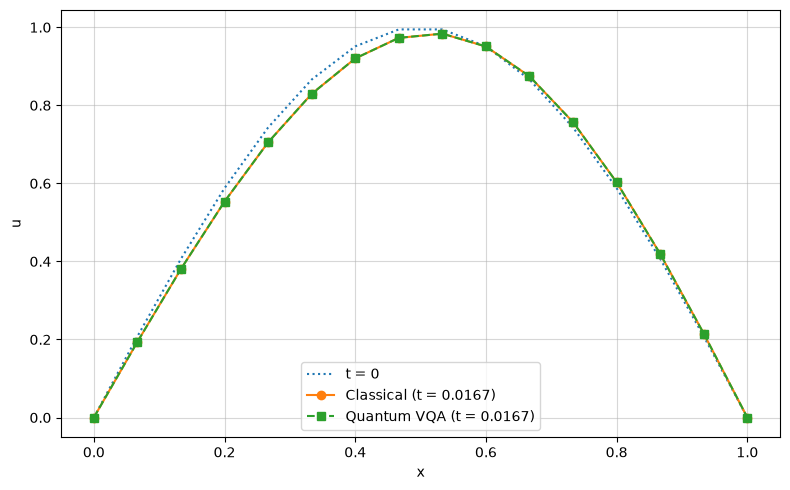

In [16]:
beta1 = c_L
beta2 = c_C * c_D * norm_j
beta_full = beta1 + beta2
omega = 2 * np.arccos(np.sqrt(beta2 / beta_full))
O_full = O_L - dt * norm_j * np.diag(sv_init) @ D1
 
theta_p = ParameterVector("θ'", qc.num_parameters)
phi_p = Parameter("φ")
 
idx = np.arange(dim_total)
keep = (((idx >> Lq) & 1) == 0) & (((idx >> A1) & 1) == 0) & (((idx >> A2) & 1) == 0)
cbit = (idx >> C) & 1
branch1_idx = (1 << C) + (np.arange(N) << DATA[0])
assert keep[branch1_idx].all() and (cbit[branch1_idx] == 1).all()
 
rng = np.random.default_rng(0)
 
 
def ansatz_gate(params, label, inverse=False):
    circuit = qc.assign_parameters(dict(zip(theta, params)))
    return (circuit.inverse() if inverse else circuit).to_gate(label=label)
 
 
def build_suffix(th_next, phi):
    s = QuantumCircuit(n_total)
    s.append(ansatz_gate(th_next, "U†(θ_j+1)", inverse=True).control(1), [C] + DATA)
    s.ry(-phi, C)
    return s
 
 
def build_step(th_j, th_next=None, phi=None):
    c = QuantumCircuit(n_total)
    c.h(C)
    c.cry(omega, C, Lq)
    c.append(ansatz_gate(th_j, "U(θ_j)").control(1), [C] + DATA)
    c.append(U_L.control(2, ctrl_state=0b11), [C, Lq] + DATA + [A1])
    c.append(U_C.control(2, ctrl_state=0b01), [C, Lq] + DATA + [A1])
    c.append(U_phi.control(2, ctrl_state=0b01), [C, Lq] + DATA + [A2])
    c.cry(-omega, C, Lq)
    if th_next is not None:
        c.compose(build_suffix(th_next, phi), inplace=True)
    return c
 
 
def z_from_probabilities(pr):
    n0 = pr[keep & (cbit == 0)].sum()
    n1 = pr[keep & (cbit == 1)].sum()
    return (n0 - n1) / (n0 + n1)
 
 
sv_pre = Statevector(build_step(theta_j))
w_chk = sv_pre.data[branch1_idx]
assert np.allclose(w_chk, O_full @ sv_init / (beta_full * np.sqrt(2)), atol=1e-8), "circuit != O_full psi / beta"
print("circuit reproduces O_full|psi>/beta_full  ✔")
 
suffix_template = build_suffix(theta_p, phi_p)
 
 
def measure_sigma_z(params, shots=None):
    th, phi = params[:-1], params[-1]
    bound = suffix_template.assign_parameters({**dict(zip(theta_p, th)), phi_p: phi})
    pr = sv_pre.evolve(bound).probabilities()
    if shots is None:
        return z_from_probabilities(pr)
    out = rng.choice(dim_total, size=shots, p=pr)
    ok = keep[out]
    n0 = np.sum(ok & (cbit[out] == 0))
    n1 = np.sum(ok & (cbit[out] == 1))
    return 0.0 if n0 + n1 == 0 else (n0 - n1) / (n0 + n1)
 
 
def cost(params, shots=None):
    return 1.0 - measure_sigma_z(params, shots)
 
 
alpha0 = 2 * sv_pre.probabilities()[keep & (cbit == 1)].sum()
phi0 = 2 * np.arctan(np.sqrt(alpha0))
 
res = minimize(cost, np.append(theta_j, phi0), method="L-BFGS-B",
               options={"maxiter": 500, "ftol": 1e-12, "gtol": 1e-9})
theta_next, phi_opt = res.x[:-1], res.x[-1]
ez = measure_sigma_z(res.x)
print(f"cost 1-<Z> = {res.fun:.3e}   <Z> = {ez:.6f}")
 
ez_full = z_from_probabilities(Statevector(build_step(theta_j, theta_next, phi_opt)).probabilities())
print(f"<Z> full circuit = {ez_full:.6f}   (suffix evolution {ez:.6f})")
 
 
def normalization_factor(alpha, phi):
    return (1 + alpha) / (2 * np.sin(phi) - (np.sqrt(alpha) - 1 / np.sqrt(alpha)) * np.cos(phi))
 
 
def fidelity_eq4(ez, alpha, phi):
    return (alpha * (ez + np.cos(phi)) + ez - np.cos(phi)) ** 2 / (4 * alpha * np.sin(phi) ** 2)
 
 
alpha_succ = np.tan(phi_opt / 2) ** 2
f_O = normalization_factor(alpha_succ, phi_opt)
F_eq4 = fidelity_eq4(ez, alpha_succ, phi_opt)
norm_j1 = beta_full * f_O * norm_j
 
psi_next = Statevector(qc.assign_parameters({theta: theta_next})).data.real
psi_exact = O_full @ sv_init
alpha_exact = np.linalg.norm(psi_exact) ** 2 / beta_full ** 2
psi_exact /= np.linalg.norm(psi_exact)
print(f"alpha from phi = {alpha_succ:.5f}   exact alpha = {alpha_exact:.5f}")
print(f"F (Eq.4, no classical data) = {F_eq4:.6f}   true fidelity = {(psi_next @ psi_exact) ** 2:.6f}")
print(f"norm_j1 from Eq.5 = {norm_j1:.6f}   classical = {np.linalg.norm(classical_solution[1]):.6f}")
 
u_quantum = norm_j1 * psi_next
plt.figure(figsize=(8, 5))
plt.plot(x, classical_solution[0], ":", label="t = 0")
plt.plot(x, classical_solution[1], "o-", label=f"Classical (t = {dt:.3g})")
plt.plot(x, u_quantum, "s--", label=f"Quantum VQA (t = {dt:.3g})")
plt.xlabel("x"); plt.ylabel("u"); plt.grid(alpha=0.5); plt.legend(); plt.tight_layout()
plt.savefig("burgers_step1.png", dpi=120)
print("max |u_quantum - u_classical| =", np.max(np.abs(u_quantum - classical_solution[1])))


In [17]:
full_circuit = build_step(theta_j, theta_next, phi_opt)
full_circuit.draw("mpl", style="clifford", scale=0.8, fold=-1).savefig("full_circuit.png", dpi=200, bbox_inches="tight")


step   1  t=0.017  <Z>=1.00000  alpha(φ)=0.5440 (exact 0.5440)  F_eq4=1.00000  F_true=1.00000  rel.L2 err=5.81e-07
step   2  t=0.033  <Z>=1.00000  alpha(φ)=0.5462 (exact 0.5462)  F_eq4=1.00000  F_true=1.00000  rel.L2 err=6.61e-07
step   3  t=0.050  <Z>=1.00000  alpha(φ)=0.5488 (exact 0.5488)  F_eq4=1.00000  F_true=1.00000  rel.L2 err=6.96e-07
step   4  t=0.067  <Z>=1.00000  alpha(φ)=0.5519 (exact 0.5519)  F_eq4=1.00000  F_true=1.00000  rel.L2 err=6.63e-07
step   5  t=0.083  <Z>=1.00000  alpha(φ)=0.5553 (exact 0.5553)  F_eq4=1.00000  F_true=1.00000  rel.L2 err=9.90e-07
step   6  t=0.100  <Z>=1.00000  alpha(φ)=0.5580 (exact 0.5580)  F_eq4=1.00000  F_true=1.00000  rel.L2 err=8.69e-07
step   7  t=0.117  <Z>=1.00000  alpha(φ)=0.5604 (exact 0.5604)  F_eq4=1.00000  F_true=1.00000  rel.L2 err=1.51e-06
step   8  t=0.133  <Z>=1.00000  alpha(φ)=0.5630 (exact 0.5630)  F_eq4=1.00000  F_true=1.00000  rel.L2 err=1.25e-06
step   9  t=0.150  <Z>=1.00000  alpha(φ)=0.5658 (exact 0.5658)  F_eq4=1.00000  F

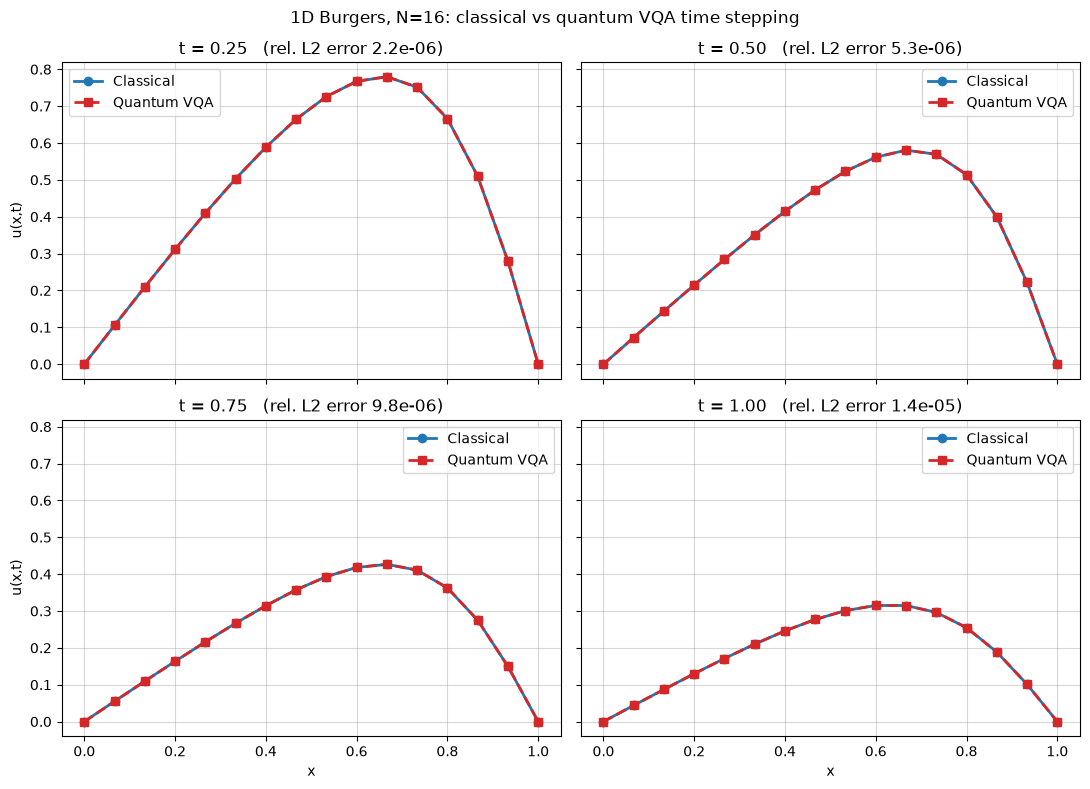

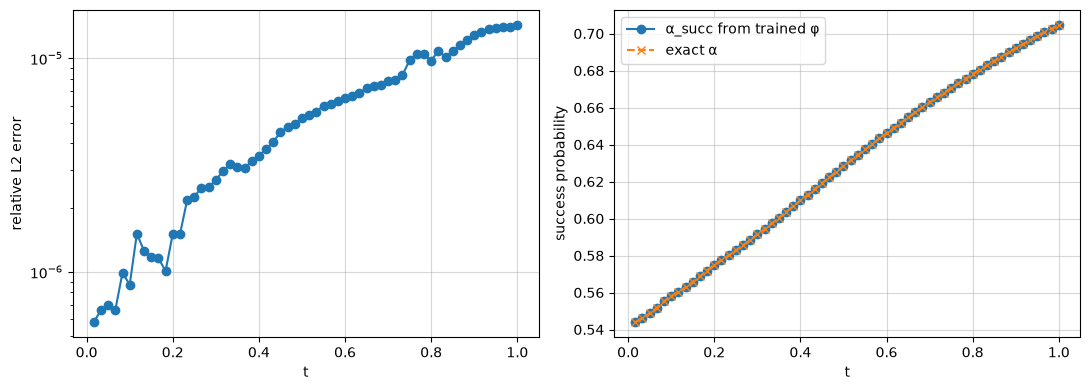

In [18]:
def ansatz_state(params):
    return Statevector(qc.assign_parameters({theta: params})).data.real
 
 
def rel_l2_error(approx, reference):
    return np.linalg.norm(approx - reference) / np.linalg.norm(reference)
 
 
def build_prefix(th_j, U_phi_j, omega_j):
    c = QuantumCircuit(n_total)
    c.h(C)
    c.append(ansatz_gate(th_j, "U(θ_j)").control(1), [C] + DATA)
    c.cry(omega_j, C, Lq)
    c.append(U_L.control(2, ctrl_state=0b11), [C, Lq] + DATA + [A1])
    c.append(U_C.control(2, ctrl_state=0b01), [C, Lq] + DATA + [A1])
    c.append(U_phi_j.control(2, ctrl_state=0b01), [C, Lq] + DATA + [A2])
    c.cry(-omega_j, C, Lq)
    return c
 
 
def sigma_z_of(params, sv_prefix, shots=None):
    th, phi = params[:-1], params[-1]
    bound = suffix_template.assign_parameters({**dict(zip(theta_p, th)), phi_p: phi})
    pr = sv_prefix.evolve(bound).probabilities()
    if shots is None:
        return z_from_probabilities(pr)
    out = rng.choice(dim_total, size=shots, p=pr)
    ok = keep[out]
    n0 = np.sum(ok & (cbit[out] == 0))
    n1 = np.sum(ok & (cbit[out] == 1))
    return 0.0 if n0 + n1 == 0 else (n0 - n1) / (n0 + n1)
 
 
def train_next_step(x0, sv_prefix, shots):
    def cost_fn(params):
        return 1.0 - sigma_z_of(params, sv_prefix, shots)
 
    if shots is None:
        return minimize(cost_fn, x0, method="L-BFGS-B",
                        options={"maxiter": 500, "ftol": 1e-12, "gtol": 1e-9})
    return minimize(cost_fn, x0, method="COBYLA",
                    options={"maxiter": 2000, "rhobeg": 0.1})
 
 
def quantum_step(th_j, norm_cur, shots=None, check=True):
    psi_j = ansatz_state(th_j)
    U_phi_j, c_D_j = block_encode(np.diag(psi_j), "U_phi")
    beta2_j = c_C * c_D_j * norm_cur
    beta_full_j = c_L + beta2_j
    omega_j = 2 * np.arccos(np.sqrt(beta2_j / beta_full_j))
 
    O_full_j = O_L - dt * norm_cur * np.diag(psi_j) @ D1
    sv_prefix = Statevector(build_prefix(th_j, U_phi_j, omega_j))
    if check:
        w_j = sv_prefix.data[branch1_idx]
        assert np.allclose(w_j, O_full_j @ psi_j / (beta_full_j * np.sqrt(2)), atol=1e-7), \
            "circuit != O_full psi / beta"
 
    alpha0_j = 2 * sv_prefix.probabilities()[keep & (cbit == 1)].sum()
    x0 = np.append(th_j, 2 * np.arctan(np.sqrt(alpha0_j)))
    result = train_next_step(x0, sv_prefix, shots)
    th_next, phi_j = result.x[:-1], result.x[-1]
    ez_j = sigma_z_of(result.x, sv_prefix, shots)
 
    alpha_j = np.tan(phi_j / 2) ** 2
    norm_next = beta_full_j * normalization_factor(alpha_j, phi_j) * norm_cur
 
    psi_exact_j = O_full_j @ psi_j
    alpha_exact_j = np.linalg.norm(psi_exact_j) ** 2 / beta_full_j ** 2
    psi_exact_j /= np.linalg.norm(psi_exact_j)
 
    info = dict(ez=ez_j,
                alpha=alpha_j,
                alpha_exact=alpha_exact_j,
                F_eq4=fidelity_eq4(ez_j, alpha_j, phi_j),
                F_true=(ansatz_state(th_next) @ psi_exact_j) ** 2,
                beta_full=beta_full_j)
    return th_next, norm_next, info
 
 
theta_cur, norm_cur = theta_j.copy(), norm_j
u_quantum_hist = [norm_cur * sv_init]
infos = []
 
for j in range(n_steps):
    theta_cur, norm_cur, info = quantum_step(theta_cur, norm_cur, shots=SHOTS)
    u_quantum_hist.append(norm_cur * ansatz_state(theta_cur))
    infos.append(info)
    err = rel_l2_error(u_quantum_hist[-1], classical_solution[j + 1])
    print(f"step {j+1:3d}  t={dt*(j+1):.3f}  <Z>={info['ez']:.5f}  alpha(φ)={info['alpha']:.4f} "
          f"(exact {info['alpha_exact']:.4f})  F_eq4={info['F_eq4']:.5f}  F_true={info['F_true']:.5f}  "
          f"rel.L2 err={err:.2e}")
 
u_quantum_hist = np.array(u_quantum_hist)
 
times_to_plot = T * np.array([0.25, 0.5, 0.75, 1.0])
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True)
for ax, t in zip(axes.ravel(), times_to_plot):
    k = int(round(t / dt))
    ax.plot(x, classical_solution[k], "o-", color="#1f77b4", lw=2, label="Classical")
    ax.plot(x, u_quantum_hist[k], "s--", color="#d62728", lw=2, label="Quantum VQA")
    ax.set_title(f"t = {t:.2f}   (rel. L2 error {rel_l2_error(u_quantum_hist[k], classical_solution[k]):.1e})")
    ax.grid(alpha=0.5)
    ax.legend()
for ax in axes[1]:
    ax.set_xlabel("x")
for ax in axes[:, 0]:
    ax.set_ylabel("u(x,t)")
plt.suptitle(f"1D Burgers, N={N}: classical vs quantum VQA time stepping")
plt.tight_layout()
plt.savefig("burgers_compare_times.png", dpi=130)
plt.show()
 
steps = np.arange(1, n_steps + 1)
rel_err = [rel_l2_error(u_quantum_hist[k], classical_solution[k]) for k in steps]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].semilogy(dt * steps, rel_err, "o-")
ax[0].set_xlabel("t"); ax[0].set_ylabel("relative L2 error"); ax[0].grid(alpha=0.5)
ax[1].plot(dt * steps, [i["alpha"] for i in infos], "o-", label="α_succ from trained φ")
ax[1].plot(dt * steps, [i["alpha_exact"] for i in infos], "x--", label="exact α")
ax[1].set_xlabel("t"); ax[1].set_ylabel("success probability"); ax[1].grid(alpha=0.5); ax[1].legend()
plt.tight_layout()
plt.savefig("burgers_error_alpha.png", dpi=130)
plt.show()
